In [21]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path("__file__").resolve().parent
DATA = ROOT / "model_trial_responses.csv"
COLORS = {"+NO axis": "#3159a7", "+O axis": "#ef202f",
          "-NO axis": "#e68600", "-O axis": "#16843e"}

data = pd.read_csv(DATA)
data

,source,sector,observation_id,seed,condition_key,image_id,test_trial,response_NO,response_O
0,familiar,+NO axis,1,0,expert,1,1,2.455794,0.267013
1,familiar,+NO axis,1,0,expert,1,2,2.047170,-0.123772
2,familiar,+NO axis,1,0,expert,1,3,0.286307,-0.537066
3,familiar,+NO axis,1,0,expert,1,4,2.187845,0.802866
4,familiar,+NO axis,1,0,expert,1,5,1.436221,0.364678
...,...,...,...,...,...,...,...,...,...
22495,novel,-NO axis,6,9,naive,3,46,1.393188,0.549251
22496,novel,-NO axis,6,9,naive,3,47,0.336096,0.064920
22497,novel,-NO axis,6,9,naive,3,48,1.282369,0.058192
22498,novel,-NO axis,6,9,naive,3,49,2.251295,-0.240835


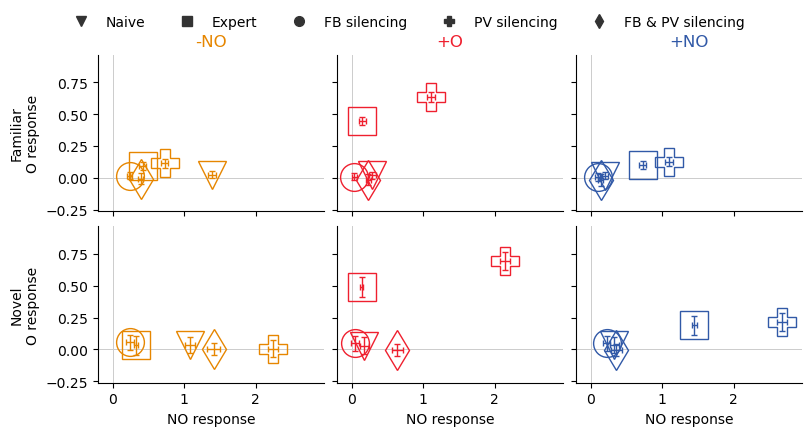

In [44]:
# One response point per condition and sector; whiskers show ±2 SEM across seeds.
# Average test trials and familiar images within a seed before estimating SEM.
from matplotlib.lines import Line2D
import numpy as np

conditions = ('naive', 'expert', 'expert_no_fb', 'expert_no_lat', 'expert_no_fb_no_lat')
markers = dict(zip(conditions, ('v', 's', 'o', 'P', 'd')))
labels = {'naive': 'Naive', 'expert': 'Expert', 'expert_no_fb': 'FB silencing',
          'expert_no_lat': 'PV silencing', 'expert_no_fb_no_lat': 'FB & PV silencing'}
sources = ('familiar', 'novel')
sectors = ('-NO axis', '+O axis', '+NO axis')

seed_means = data.groupby(['source', 'sector', 'condition_key', 'seed'], as_index=False)[
    ['response_NO', 'response_O']].mean()
summary = seed_means.groupby(['source', 'sector', 'condition_key'], as_index=False).agg(
    NO=('response_NO', 'mean'), O=('response_O', 'mean'),
    NO_sem=('response_NO', 'sem'), O_sem=('response_O', 'sem'),
    n_seeds=('seed', 'nunique'))

fig, axes = plt.subplots(2, 3, figsize=(8, 4), sharex=True, sharey=True, layout='constrained')
for i, source in enumerate(sources):
    for j, sector in enumerate(sectors):
        ax = axes[i, j]
        ax.axhline(0, color='0.8', lw=0.7)
        ax.axvline(0, color='0.8', lw=0.7)
        for condition in conditions:
            point = summary.loc[summary.source.eq(source) & summary.sector.eq(sector) &
                                summary.condition_key.eq(condition)].iloc[0]
            ax.errorbar(point.NO, point.O, xerr=2 * point.NO_sem, yerr=2 * point.O_sem,
                        fmt=markers[condition], color=COLORS[sector], markersize=20, fillstyle = 'none',
                        elinewidth=1, capsize=2)
        if i == 0:
            ax.set_title(sector.replace(' axis', ''), color=COLORS[sector])
        if j == 0:
            ax.set_ylabel(f'{source.capitalize()}\nO response')
        if i == 1:
            ax.set_xlabel('NO response')
        ax.spines[['top', 'right']].set_visible(False)

xlo = min(0, (summary.NO - 2 * summary.NO_sem).min()) - 0.2
xhi = (summary.NO + 2 * summary.NO_sem).max() + 0.2
ylo = min(0, (summary.O - 2 * summary.O_sem).min()) - 0.2
yhi = (summary.O + 2 * summary.O_sem).max() + 0.2
for ax in axes.flat:
    ax.set(xlim=(xlo, xhi), ylim=(ylo, yhi))
fig.legend([Line2D([], [], marker=markers[c], color='0.2', linestyle='none', markersize=7)
            for c in conditions], [labels[c] for c in conditions],
           loc='upper center', bbox_to_anchor=(0.5, 1.07), ncol=5, frameon=False)

output = DATA.parent / 'figures'
output.mkdir(exist_ok=True)
summary.to_csv(output / 'silencing_response_summary.csv', index=False)
for extension in ('png', 'svg'):
    fig.savefig(output / f'silencing_response_points.{extension}', dpi=200, bbox_inches='tight')
plt.show()

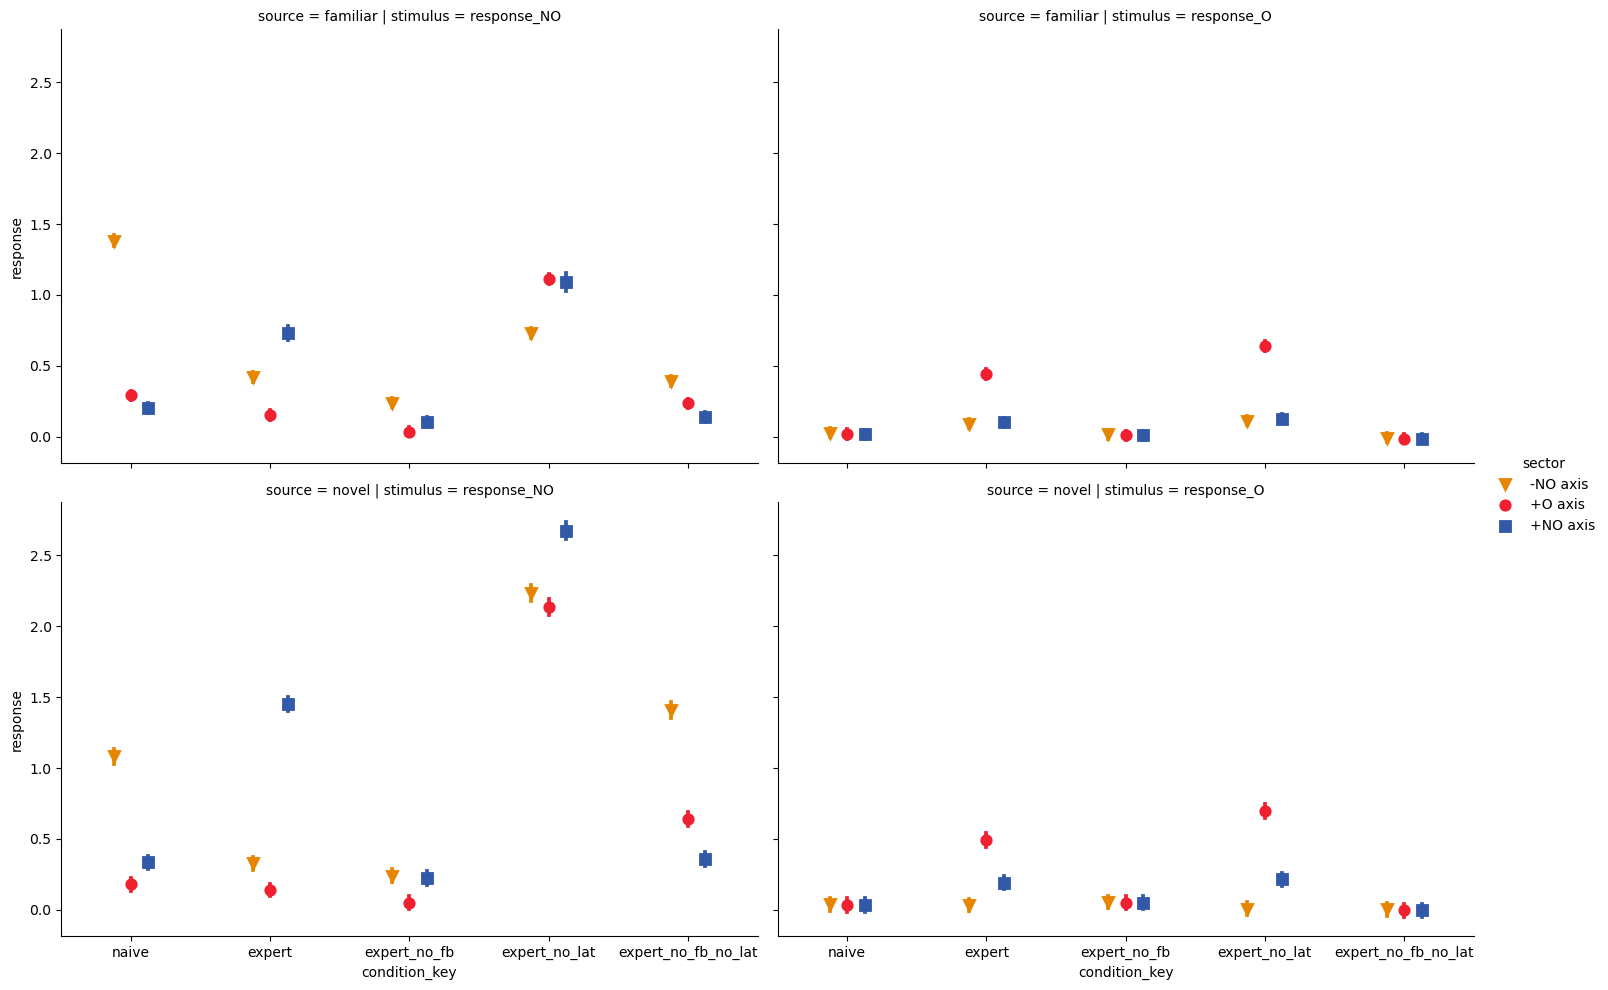

In [ ]:
dat = pd.melt(data, 
        id_vars = [col for col in data.columns if "response" not in col],
        value_vars = [col for col in data.columns if "response" in col],
        var_name= 'stimulus',
        value_name='response'
        )
# dat['response'] = dat.response.clip(upper=3)
sns.catplot(dat, col = 'stimulus', row = 'source', y = 'response', x = 'condition_key', hue = 'sector', 
            # kind = 'bar', 
            kind = 'point', dodge = .25, 
            # linestyles = ['-', '--', ':'],
            linestyle = 'none',
            markers = ['v', 'o', 's'], 
            errorbar = ('se', 2),
            order = ['naive', 'expert', 'expert_no_fb', 'expert_no_lat', 'expert_no_fb_no_lat'],
            hue_order = ['-NO axis', '+O axis', '+NO axis'],
            palette=COLORS,
            aspect = 1.5)

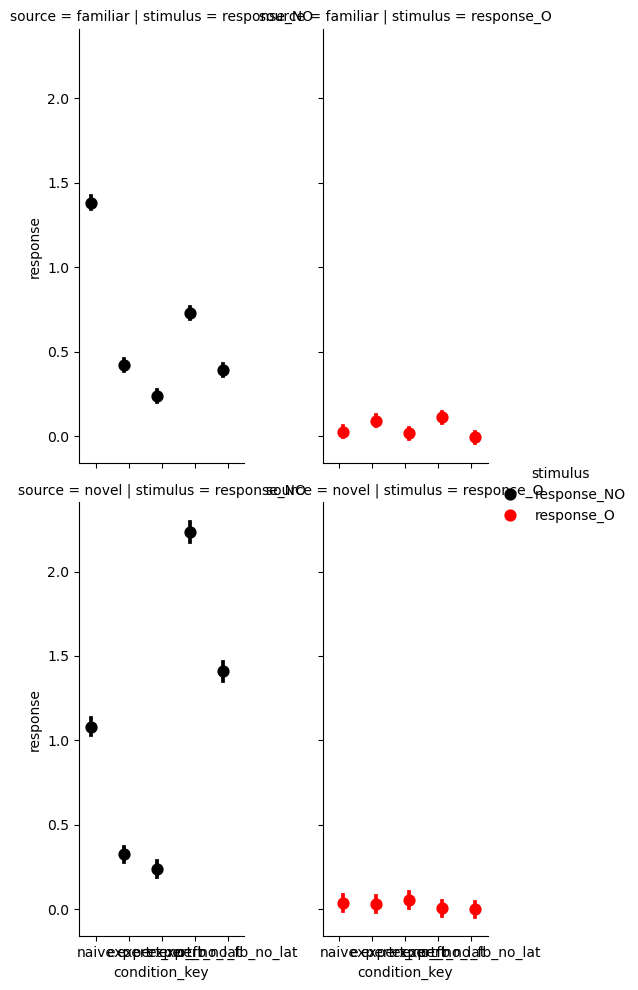

In [26]:
sns.catplot(dat.loc[dat.sector.eq('-NO axis')], col = 'stimulus', row = 'source', y = 'response', x = 'condition_key', 
            hue = 'stimulus', 
            # kind = 'bar', 
            kind = 'point', dodge = .25, 
            # linestyles = ['-', '--', ':'],
            linestyle = 'none',
            markers = 'o', 
            errorbar = ('se', 2),
            order = ['naive', 'expert', 'expert_no_fb', 'expert_no_lat', 'expert_no_fb_no_lat'],
            # hue_order = ['-NO axis', '+O axis', '+NO axis'],
            palette={'response_NO':"black", 'response_O':'red'},
            aspect = 0.5,
            height = 5
            )

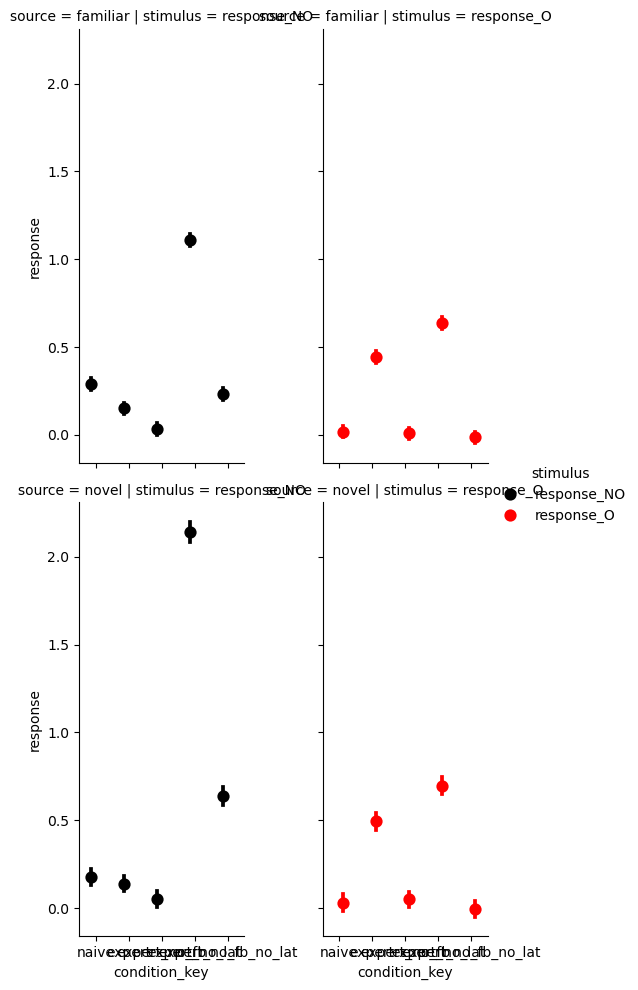

In [27]:
sns.catplot(dat.loc[dat.sector.eq('+O axis')], col = 'stimulus', row = 'source', y = 'response', x = 'condition_key', 
            hue = 'stimulus', 
            # kind = 'bar', 
            kind = 'point', dodge = .25, 
            # linestyles = ['-', '--', ':'],
            linestyle = 'none',
            markers = 'o', 
            errorbar = ('se', 2),
            order = ['naive', 'expert', 'expert_no_fb', 'expert_no_lat', 'expert_no_fb_no_lat'],
            # hue_order = ['-NO axis', '+O axis', '+NO axis'],
            palette={'response_NO':"black", 'response_O':'red'},
            aspect = 0.5,
            height = 5
            )

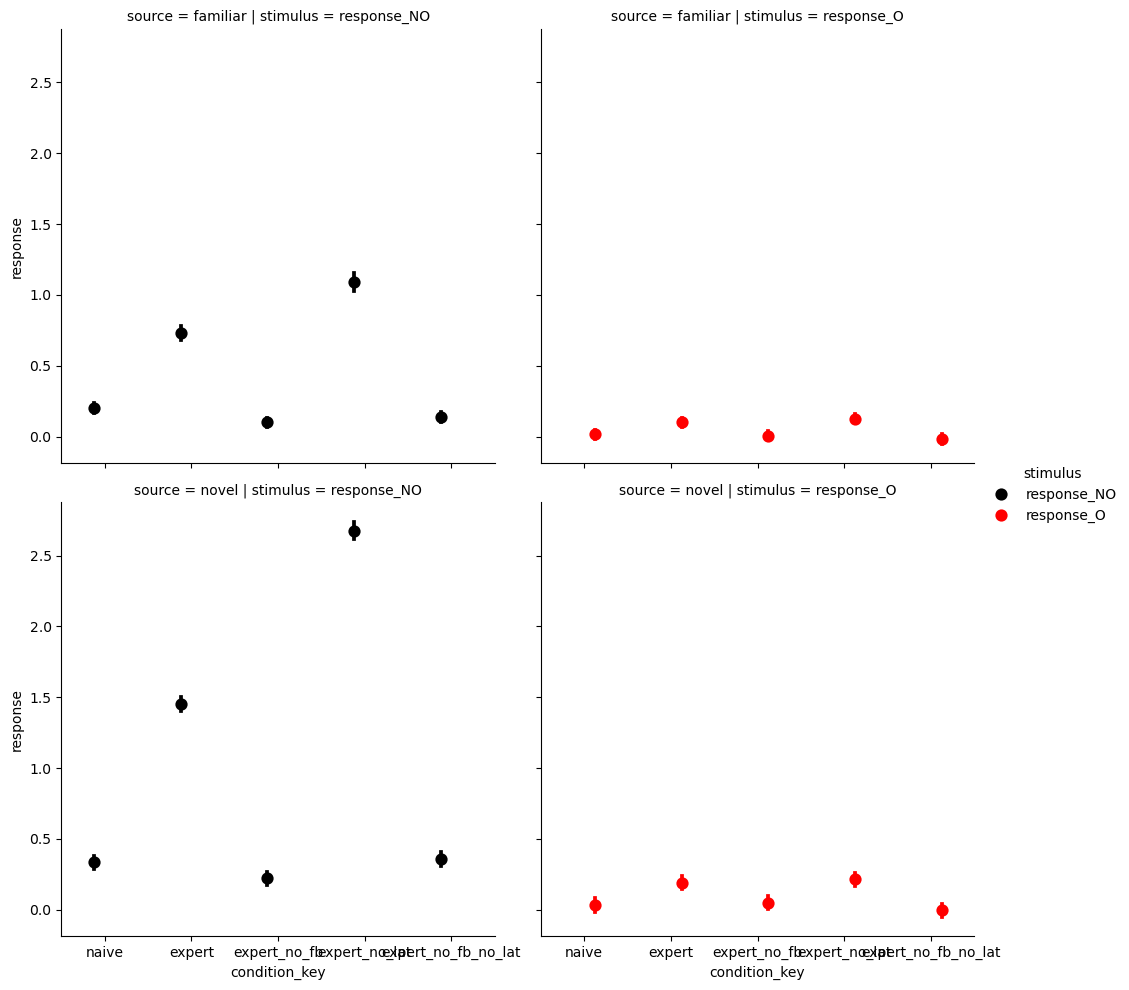

In [28]:
sns.catplot(dat.loc[dat.sector.eq('+NO axis')], col = 'stimulus', row = 'source', y = 'response', x = 'condition_key', 
            hue = 'stimulus', 
            # kind = 'bar', 
            kind = 'point', dodge = .25, 
            # linestyles = ['-', '--', ':'],
            linestyle = 'none',
            markers = 'o', 
            errorbar = ('se', 2),
            order = ['naive', 'expert', 'expert_no_fb', 'expert_no_lat', 'expert_no_fb_no_lat'],
            # hue_order = ['-NO axis', '+O axis', '+NO axis'],
            palette={'response_NO':"black", 'response_O':'red'},
            aspect = 1.0,
            height = 5
            )